# TAWOS Problem Statement 10 — BERT + SBERT Temporal Story-Point Estimation

This notebook implements the complete assigned experiment:

1. Stream the 4.31 GB TAWOS SQL dump and retain only modelling fields.
2. Select one project and create an older 80% development / newest 20% test split.
3. Create five expanding-window temporal validation folds within development data.
4. Extract and cache BERT and SBERT embeddings.
5. Compare BERT-only, SBERT-only, and combined BERT+SBERT regression models.
6. Report MAE and MdAE for validation folds and the final held-out test set.
7. Save datasets, manifests, embeddings, models, predictions, tables, and plots to Drive.

**Before running:** place `TAWOS.sql` at
`MyDrive/TAWOS_NLP/data/raw/TAWOS.sql`. Use a GPU Colab runtime for embedding extraction.



In [1]:
# Install only what a standard Colab runtime may not already provide.
import subprocess
import sys

subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "transformers>=4.44,<6",
        "sentence-transformers>=3,<6",
    ]
)



0

In [2]:
from __future__ import annotations

import copy
import csv
import hashlib
import json
import math
import mmap
import os
import random
import re
import shutil
import statistics
import time
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime
from pathlib import Path
from typing import Any, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from google.colab import drive
from sentence_transformers import SentenceTransformer
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModel, AutoTokenizer

drive.mount("/content/drive")

# Edit these settings if needed. PROJECT_KEY=None automatically selects the
# project with the largest leakage-safe labelled sample.
DRIVE_ROOT = Path("/content/drive/MyDrive/TAWOS_NLP")
SQL_IN_DRIVE = DRIVE_ROOT / "data/raw/TAWOS.sql"
PROJECT_KEY = None  # Example: "MESOS"
TEST_FRACTION = 0.20
N_FOLDS = 5
SEED = 42
BERT_MODEL = "bert-base-uncased"
SBERT_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
MAX_LENGTH = 256
EMBED_BATCH_SIZE = 16
TRAIN_BATCH_SIZE = 64
MAX_EPOCHS = 50
PATIENCE = 7
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

PROCESSED_DIR = DRIVE_ROOT / "data/processed"
EMBEDDING_DIR = DRIVE_ROOT / "artifacts/embeddings"
MODEL_DIR = DRIVE_ROOT / "artifacts/models"
RESULTS_DIR = DRIVE_ROOT / "results"
for directory in (PROCESSED_DIR, EMBEDDING_DIR, MODEL_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type != "cuda":
    print("Warning: choose Runtime > Change runtime type > GPU before extracting embeddings.")
print("Drive root:", DRIVE_ROOT)



Mounted at /content/drive
Device: cuda
Drive root: /content/drive/MyDrive/TAWOS_NLP


## 1. Stream the TAWOS SQL dump

The dump contains extremely long single-line `INSERT` statements, so ordinary
line-by-line parsing can exhaust memory. The parser below memory-maps the local
copy and decodes only the required columns. It never modifies the SQL file.



In [3]:
class SQLDumpError(ValueError):
    pass


_ESCAPED_BYTE = re.compile(rb"\\(.)", re.DOTALL)
_MYSQL_ESCAPES = {
    b"0": b"\x00", b"b": b"\b", b"n": b"\n", b"r": b"\r",
    b"t": b"\t", b"Z": b"\x1a", b"'": b"'", b'"': b'"',
    b"\\": b"\\", b"%": b"%", b"_": b"_",
}


def _unescape_mysql(raw: bytes) -> str:
    return _ESCAPED_BYTE.sub(
        lambda match: _MYSQL_ESCAPES.get(match.group(1), match.group(1)), raw
    ).decode("utf-8", errors="replace")


def _closing_quote(data: mmap.mmap, start: int, limit: int) -> int:
    position = start
    while True:
        quote = data.find(b"'", position, limit)
        if quote < 0:
            raise SQLDumpError(f"Unterminated quoted value near byte {start}")
        backslashes = 0
        cursor = quote - 1
        while cursor >= start and data[cursor] == 92:
            backslashes += 1
            cursor -= 1
        if backslashes % 2 == 0:
            return quote
        position = quote + 1


def iter_insert_rows(path: Path, table: str, columns: Sequence[int]):
    """Yield selected zero-based columns from all INSERTs for one table."""
    marker = f"INSERT INTO `{table}` VALUES ".encode()
    selected = tuple(columns)
    selected_set = set(selected)
    with path.open("rb") as handle, mmap.mmap(handle.fileno(), 0, access=mmap.ACCESS_READ) as data:
        search_from = 0
        limit = len(data)
        while True:
            statement = data.find(marker, search_from)
            if statement < 0:
                return
            position = statement + len(marker)
            row_number = 0
            while position < limit:
                while position < limit and data[position] in b" \t\r\n,":
                    position += 1
                if position >= limit:
                    raise SQLDumpError(f"Unterminated INSERT for {table}")
                if data[position] == 59:
                    search_from = position + 1
                    break
                if data[position] != 40:
                    raise SQLDumpError(f"Expected '(' in {table} row {row_number + 1}")
                position += 1
                field_number = 0
                values = {}
                while True:
                    while position < limit and data[position] in b" \t\r\n":
                        position += 1
                    wanted = field_number in selected_set
                    if data[position] == 39:
                        start = position + 1
                        quote = _closing_quote(data, start, limit)
                        value = _unescape_mysql(data[start:quote]) if wanted else None
                        position = quote + 1
                    else:
                        comma = data.find(b",", position, limit)
                        close = data.find(b")", position, limit)
                        candidates = [item for item in (comma, close) if item >= 0]
                        if not candidates:
                            raise SQLDumpError(f"Unterminated value in {table} row {row_number + 1}")
                        end = min(candidates)
                        raw = data[position:end].strip()
                        value = None if raw.upper() == b"NULL" else raw.decode(errors="replace")
                        position = end
                    if wanted:
                        values[field_number] = value
                    field_number += 1
                    while position < limit and data[position] in b" \t\r\n":
                        position += 1
                    if data[position] == 44:
                        position += 1
                        continue
                    if data[position] == 41:
                        position += 1
                        break
                    raise SQLDumpError(
                        f"Unexpected delimiter in {table} row {row_number + 1}, field {field_number}"
                    )
                row_number += 1
                missing = [index for index in selected if index not in values]
                if missing:
                    raise SQLDumpError(f"{table} row {row_number} lacks columns {missing}")
                yield tuple(values[index] for index in selected)


def clean_text(value: str | None) -> str:
    return " ".join((value or "").replace("\x00", " ").split())


def changed(value: str | None) -> bool:
    return value not in (None, "", "0")


PROJECT_COLUMNS = (0, 1, 2)
ISSUE_COLUMNS = (0, 2, 4, 6, 12, 16, 21, 22, 23, 28)
OUTPUT_COLUMNS = [
    "issue_id", "issue_key", "project_id", "project_key", "project_name",
    "creation_date", "story_point", "title", "description_text", "input_text",
]


def extract_tawos(sql_path: Path, output_dir: Path) -> dict[str, Any]:
    projects = {
        project_id: (project_key, project_name or project_key)
        for project_id, project_key, project_name in iter_insert_rows(
            sql_path, "Project", PROJECT_COLUMNS
        )
        if project_id and project_key
    }
    if not projects:
        raise SQLDumpError("No Project records found")

    output_dir.mkdir(parents=True, exist_ok=True)
    eligible_path = output_dir / "eligible_issues.csv"
    excluded = Counter()
    dates = defaultdict(list)
    labels = defaultdict(list)
    with eligible_path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=OUTPUT_COLUMNS)
        writer.writeheader()
        for row in iter_insert_rows(sql_path, "Issue", ISSUE_COLUMNS):
            issue_id, issue_key, title, description, created, story, tc, dc, sc, project_id = row
            if project_id not in projects:
                excluded["unknown_project"] += 1
                continue
            title, description = clean_text(title), clean_text(description)
            if not title and not description:
                excluded["missing_text"] += 1
                continue
            if not created:
                excluded["missing_creation_date"] += 1
                continue
            try:
                created = datetime.fromisoformat(created).isoformat(sep=" ")
            except ValueError:
                excluded["invalid_creation_date"] += 1
                continue
            try:
                label = float(story) if story is not None else math.nan
            except ValueError:
                label = math.nan
            if not math.isfinite(label) or label < 0:
                excluded["missing_or_invalid_story_point"] += 1
                continue
            if any(changed(flag) for flag in (tc, dc, sc)):
                excluded["changed_after_estimation"] += 1
                continue
            project_key, project_name = projects[project_id]
            writer.writerow(
                {
                    "issue_id": issue_id,
                    "issue_key": issue_key,
                    "project_id": project_id,
                    "project_key": project_key,
                    "project_name": project_name,
                    "creation_date": created,
                    "story_point": label,
                    "title": title,
                    "description_text": description,
                    "input_text": " [SEP] ".join(part for part in (title, description) if part),
                }
            )
            dates[project_key].append(created)
            labels[project_key].append(label)

    profile_rows = []
    project_names = {key: name for key, name in projects.values()}
    for key in sorted(project_names):
        ys = labels.get(key, [])
        ds = dates.get(key, [])
        profile_rows.append(
            {
                "project_key": key,
                "project_name": project_names[key],
                "eligible_issues": len(ys),
                "earliest_creation": min(ds) if ds else None,
                "latest_creation": max(ds) if ds else None,
                "median_story_point": statistics.median(ys) if ys else None,
                "mean_story_point": statistics.fmean(ys) if ys else None,
            }
        )
    profile = pd.DataFrame(profile_rows).sort_values("eligible_issues", ascending=False)
    profile.to_csv(output_dir / "project_profile.csv", index=False)
    summary = {
        "eligible_total": int(profile["eligible_issues"].sum()),
        "excluded": dict(excluded),
        "created_at_utc": datetime.utcnow().isoformat(),
    }
    (output_dir / "preparation_summary.json").write_text(json.dumps(summary, indent=2))
    return summary



In [4]:
# Copy the SQL dump to Colab's local disk only when compact cached data does not
# already exist. This greatly speeds memory-mapped reading from Google Drive.
ELIGIBLE_CSV = PROCESSED_DIR / "eligible_issues.csv"
PROFILE_CSV = PROCESSED_DIR / "project_profile.csv"

if not ELIGIBLE_CSV.exists() or not PROFILE_CSV.exists():
    if not SQL_IN_DRIVE.is_file():
        raise FileNotFoundError(
            f"Place TAWOS.sql at {SQL_IN_DRIVE} and rerun this cell."
        )
    local_sql = Path("/content/TAWOS.sql")
    if not local_sql.exists() or local_sql.stat().st_size != SQL_IN_DRIVE.stat().st_size:
        print("Copying TAWOS.sql from Drive to Colab temporary storage...")
        shutil.copy2(SQL_IN_DRIVE, local_sql)
    local_output = Path("/content/tawos_processed")
    started = time.time()
    summary = extract_tawos(local_sql, local_output)
    shutil.copy2(local_output / "eligible_issues.csv", ELIGIBLE_CSV)
    shutil.copy2(local_output / "project_profile.csv", PROFILE_CSV)
    shutil.copy2(local_output / "preparation_summary.json", PROCESSED_DIR / "preparation_summary.json")
    print(f"Extraction completed in {(time.time() - started) / 60:.1f} minutes")
else:
    print("Using cached compact dataset:", ELIGIBLE_CSV)

profile = pd.read_csv(PROFILE_CSV)
display(profile.head(15))

if PROJECT_KEY is None:
    candidates = profile.loc[profile["eligible_issues"] > 0]
    if candidates.empty:
        raise ValueError("No project has eligible labelled issues")
    SELECTED_PROJECT = str(candidates.iloc[0]["project_key"])
else:
    SELECTED_PROJECT = PROJECT_KEY.upper()
    if SELECTED_PROJECT not in set(profile["project_key"]):
        raise ValueError(f"Unknown project key: {SELECTED_PROJECT}")
print("Selected project:", SELECTED_PROJECT)



Copying TAWOS.sql from Drive to Colab temporary storage...


/tmp/ipykernel_349/2286859881.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at_utc": datetime.utcnow().isoformat(),


Extraction completed in 0.8 minutes


,project_key,project_name,eligible_issues,earliest_creation,latest_creation,median_story_point,mean_story_point
0,DM,Lsstcorp Data management,14782,2014-03-04 14:51:50,2020-10-22 14:51:07,2.0,5.984297
1,EVG,The MongoDB Engineering,4739,2014-06-03 22:41:30,2020-10-21 22:09:03,2.0,1.738658
2,MULE,Mule,3065,2009-02-28 00:59:32,2019-10-15 17:39:51,3.0,4.148450
3,TIMOB,The Titanium SDK,2800,2011-04-15 02:27:30,2020-10-17 15:41:42,5.0,7.697500
4,XD,Spring XD,2718,2013-04-12 06:43:53,2018-11-16 15:57:31,3.0,4.425681
5,TISTUD,Appcelerator Studio,2434,2011-03-01 11:50:44,2020-05-12 02:15:14,5.0,5.194330
6,MESOS,Apache Mesos,2333,2013-02-04 18:27:52,2020-08-12 10:24:47,3.0,3.035062
7,DNN,DotNetNuke Platform,1905,2012-01-16 07:19:00,2018-03-08 09:39:04,2.0,2.023465
8,NEXUS,Sonatype Nexus,1178,2008-08-14 15:14:26,2020-03-05 07:56:25,1.0,1.767063
9,TIDOC,Titanium Mobile Platform,1031,2011-12-28 17:23:47,2020-02-18 10:26:41,3.0,4.306984


Selected project: DM


## 2. Reproducible temporal split

Equal creation timestamps are kept on the same side of each boundary. The
newest 20% is never used for model selection. Five validation runs use an
expanding training window followed by a strictly later validation window.



{
  "project_key": "DM",
  "test_fraction": 0.2,
  "development_count": 11825,
  "test_count": 2957,
  "development_dates": [
    "2014-03-04 14:51:50",
    "2019-11-07 22:44:03"
  ],
  "test_dates": [
    "2019-11-07 22:50:12",
    "2020-10-22 14:51:07"
  ]
}


,fold,train_start,train_end,validation_start,validation_end,train_dates,validation_dates
0,1,0,1952,1952,3907,"[2014-03-04 14:51:50, 2016-02-03 12:03:14]","[2016-02-03 12:17:28, 2016-11-30 11:36:52]"
1,2,0,3907,3907,5869,"[2014-03-04 14:51:50, 2016-11-30 11:36:52]","[2016-11-30 11:42:04, 2017-09-28 13:26:26]"
2,3,0,5869,5869,7862,"[2014-03-04 14:51:50, 2017-09-28 13:26:26]","[2017-09-28 15:24:23, 2018-08-06 13:33:54]"
3,4,0,7862,7862,9856,"[2014-03-04 14:51:50, 2018-08-06 13:33:54]","[2018-08-06 15:15:13, 2019-04-08 12:41:58]"
4,5,0,9856,9856,11825,"[2014-03-04 14:51:50, 2019-04-08 12:41:58]","[2019-04-08 12:42:08, 2019-11-07 22:44:03]"


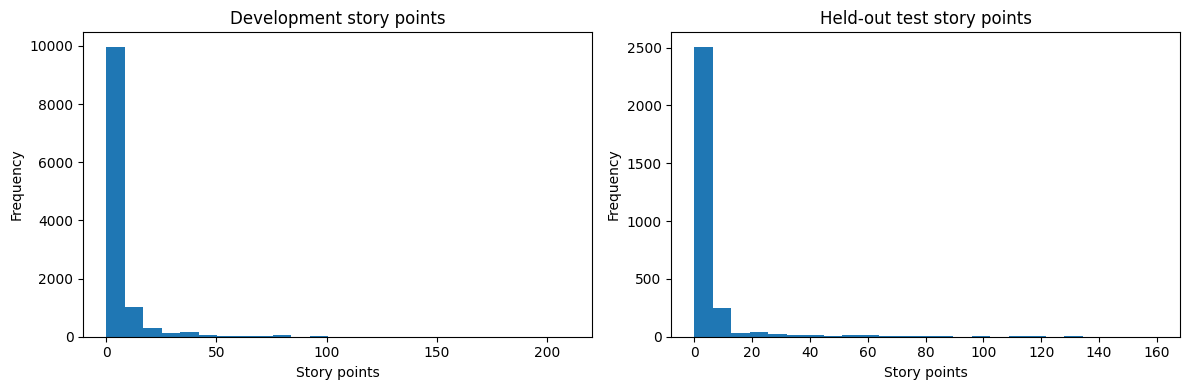

In [5]:
@dataclass(frozen=True)
class TemporalFold:
    fold: int
    train_start: int
    train_end: int
    validation_start: int
    validation_end: int


def chronological_holdout(frame: pd.DataFrame, test_fraction: float):
    ordered = frame.sort_values(["creation_date", "issue_id"]).reset_index(drop=True)
    test_size = max(1, math.ceil(len(ordered) * test_fraction))
    cut = len(ordered) - test_size
    boundary = ordered.loc[cut, "creation_date"]
    while cut > 0 and ordered.loc[cut - 1, "creation_date"] == boundary:
        cut -= 1
    if cut == 0:
        raise ValueError("Temporal boundary leaves no development data")
    return ordered.iloc[:cut].copy(), ordered.iloc[cut:].copy()


def expanding_folds(dates: Sequence[str], n_folds: int):
    if list(dates) != sorted(dates):
        raise ValueError("Development dates must be sorted")
    starts = [0] + [i for i in range(1, len(dates)) if dates[i] != dates[i - 1]]
    required = n_folds + 1
    if len(starts) < required:
        raise ValueError(f"At least {required} distinct timestamps are required")
    starts.append(len(dates))
    groups = len(starts) - 1
    group_boundaries = [(i * groups) // required for i in range(required)] + [groups]
    boundaries = [starts[i] for i in group_boundaries]
    return [
        TemporalFold(i + 1, 0, boundaries[i + 1], boundaries[i + 1], boundaries[i + 2])
        for i in range(n_folds)
    ]


all_eligible = pd.read_csv(ELIGIBLE_CSV)
project_data = all_eligible.loc[all_eligible["project_key"] == SELECTED_PROJECT].copy()
project_data["creation_date"] = pd.to_datetime(project_data["creation_date"]).dt.strftime(
    "%Y-%m-%d %H:%M:%S"
)
development, held_out_test = chronological_holdout(project_data, TEST_FRACTION)
folds = expanding_folds(development["creation_date"].tolist(), N_FOLDS)

PROJECT_DIR = PROCESSED_DIR / SELECTED_PROJECT
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
development.to_csv(PROJECT_DIR / "development.csv", index=False)
held_out_test.to_csv(PROJECT_DIR / "test.csv", index=False)

manifest = {
    "project_key": SELECTED_PROJECT,
    "test_fraction": TEST_FRACTION,
    "development_count": len(development),
    "test_count": len(held_out_test),
    "development_dates": [development.iloc[0]["creation_date"], development.iloc[-1]["creation_date"]],
    "test_dates": [held_out_test.iloc[0]["creation_date"], held_out_test.iloc[-1]["creation_date"]],
    "folds": [],
}
for fold in folds:
    record = asdict(fold)
    record["train_dates"] = [
        development.iloc[fold.train_start]["creation_date"],
        development.iloc[fold.train_end - 1]["creation_date"],
    ]
    record["validation_dates"] = [
        development.iloc[fold.validation_start]["creation_date"],
        development.iloc[fold.validation_end - 1]["creation_date"],
    ]
    manifest["folds"].append(record)
(PROJECT_DIR / "split_manifest.json").write_text(json.dumps(manifest, indent=2))

print(json.dumps({key: value for key, value in manifest.items() if key != "folds"}, indent=2))
display(pd.DataFrame(manifest["folds"]))

# Basic label inspection for the report.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
development["story_point"].plot.hist(ax=axes[0], bins=25, title="Development story points")
held_out_test["story_point"].plot.hist(ax=axes[1], bins=25, title="Held-out test story points")
for axis in axes:
    axis.set_xlabel("Story points")
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"{SELECTED_PROJECT}_label_distribution.png", dpi=160)
plt.show()



## 3. Extract and cache BERT and SBERT representations

BERT produces contextual token representations; masked mean pooling converts
them to one issue vector. SBERT directly produces a semantic sentence vector.
The combined representation concatenates the two vectors. Encoder weights are
frozen in the default experiment so all folds can reuse identical embeddings.



In [6]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(False)


def dataset_fingerprint(frame: pd.DataFrame) -> str:
    digest = hashlib.sha256()
    for row in frame[["issue_key", "input_text"]].itertuples(index=False):
        digest.update(str(row.issue_key).encode())
        digest.update(b"\0")
        digest.update(str(row.input_text).encode())
        digest.update(b"\n")
    return digest.hexdigest()


def mean_pool(last_hidden_state: torch.Tensor, attention_mask: torch.Tensor):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    return (last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1e-9)


def extract_bert(texts: list[str], model_name: str, batch_size: int):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    outputs = []
    with torch.inference_mode():
        for start in range(0, len(texts), batch_size):
            batch = texts[start : start + batch_size]
            encoded = tokenizer(
                batch, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt"
            )
            encoded = {key: value.to(DEVICE) for key, value in encoded.items()}
            hidden = model(**encoded).last_hidden_state
            outputs.append(mean_pool(hidden, encoded["attention_mask"]).cpu().numpy())
            if start % (batch_size * 20) == 0:
                print(f"BERT: {min(start + batch_size, len(texts))}/{len(texts)}")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return np.concatenate(outputs).astype("float32")


def extract_sbert(texts: list[str], model_name: str, batch_size: int):
    model = SentenceTransformer(model_name, device=str(DEVICE))
    values = model.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=False,
    )
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return values.astype("float32")


combined_rows = pd.concat([development, held_out_test], ignore_index=True)
fingerprint = dataset_fingerprint(combined_rows)
PROJECT_EMBEDDINGS = EMBEDDING_DIR / SELECTED_PROJECT
PROJECT_EMBEDDINGS.mkdir(parents=True, exist_ok=True)
embedding_manifest_path = PROJECT_EMBEDDINGS / "embedding_manifest.json"
cache_valid = False
if embedding_manifest_path.exists():
    old_manifest = json.loads(embedding_manifest_path.read_text())
    cache_valid = (
        old_manifest.get("fingerprint") == fingerprint
        and old_manifest.get("bert_model") == BERT_MODEL
        and old_manifest.get("sbert_model") == SBERT_MODEL
        and old_manifest.get("max_length") == MAX_LENGTH
        and (PROJECT_EMBEDDINGS / "bert.npy").exists()
        and (PROJECT_EMBEDDINGS / "sbert.npy").exists()
    )

if cache_valid:
    print("Using cached embeddings")
    bert_embeddings = np.load(PROJECT_EMBEDDINGS / "bert.npy")
    sbert_embeddings = np.load(PROJECT_EMBEDDINGS / "sbert.npy")
else:
    set_seed(SEED)
    texts = combined_rows["input_text"].fillna("").astype(str).tolist()
    bert_embeddings = extract_bert(texts, BERT_MODEL, EMBED_BATCH_SIZE)
    np.save(PROJECT_EMBEDDINGS / "bert.npy", bert_embeddings)
    sbert_embeddings = extract_sbert(texts, SBERT_MODEL, EMBED_BATCH_SIZE)
    np.save(PROJECT_EMBEDDINGS / "sbert.npy", sbert_embeddings)
    embedding_manifest_path.write_text(
        json.dumps(
            {
                "fingerprint": fingerprint,
                "rows": len(combined_rows),
                "development_rows": len(development),
                "bert_model": BERT_MODEL,
                "sbert_model": SBERT_MODEL,
                "max_length": MAX_LENGTH,
                "bert_shape": list(bert_embeddings.shape),
                "sbert_shape": list(sbert_embeddings.shape),
            },
            indent=2,
        )
    )

assert len(bert_embeddings) == len(combined_rows) == len(sbert_embeddings)
print("BERT shape:", bert_embeddings.shape)
print("SBERT shape:", sbert_embeddings.shape)



config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (14 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/924 [00:00<?, ?it/s]

BERT shape: (14782, 768)
SBERT shape: (14782, 384)


## 4. Five-fold validation and final held-out evaluation

Each fold fits feature and target standardisation using training records only.
A three-layer dense regression head is trained with Smooth L1 loss. Early
stopping chooses an epoch count from development folds; the final model is
retrained on all development records and evaluated once on the newest 20%.



In [7]:
class RegressionHead(nn.Module):
    def __init__(self, input_dim: int):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 1),
        )

    def forward(self, features):
        return self.network(features).squeeze(-1)


def absolute_metrics(actual, predicted):
    predicted = np.maximum(0.0, np.asarray(predicted, dtype=float))
    errors = np.abs(np.asarray(actual, dtype=float) - predicted)
    return {"mae": float(errors.mean()), "mdae": float(np.median(errors))}, predicted


def fit_scalers(features: np.ndarray, labels: np.ndarray):
    x_mean = features.mean(axis=0, keepdims=True)
    x_std = features.std(axis=0, keepdims=True)
    x_std[x_std < 1e-8] = 1.0
    y_mean = float(labels.mean())
    y_std = float(labels.std()) or 1.0
    return x_mean, x_std, y_mean, y_std


def predict_model(model, features, x_mean, x_std, y_mean, y_std):
    normalized = ((features - x_mean) / x_std).astype("float32")
    model.eval()
    predictions = []
    with torch.inference_mode():
        for start in range(0, len(normalized), 1024):
            batch = torch.from_numpy(normalized[start : start + 1024]).to(DEVICE)
            predictions.append(model(batch).cpu().numpy())
    return np.concatenate(predictions) * y_std + y_mean


def train_fold(features, labels, train_indices, validation_indices, seed):
    set_seed(seed)
    x_train, y_train = features[train_indices], labels[train_indices]
    x_val, y_val = features[validation_indices], labels[validation_indices]
    x_mean, x_std, y_mean, y_std = fit_scalers(x_train, y_train)
    x_train = ((x_train - x_mean) / x_std).astype("float32")
    y_train_normalized = ((y_train - y_mean) / y_std).astype("float32")
    dataset = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train_normalized))
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, generator=generator)

    model = RegressionHead(features.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_fn = nn.SmoothL1Loss()
    best_state, best_mae, best_epoch, stale = None, float("inf"), 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(DEVICE), batch_labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(batch_features), batch_labels)
            loss.backward()
            optimizer.step()
        raw_predictions = predict_model(model, x_val, x_mean, x_std, y_mean, y_std)
        metrics, _ = absolute_metrics(y_val, raw_predictions)
        if metrics["mae"] < best_mae - 1e-6:
            best_mae = metrics["mae"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    model.load_state_dict(best_state)
    raw_predictions = predict_model(model, x_val, x_mean, x_std, y_mean, y_std)
    metrics, _ = absolute_metrics(y_val, raw_predictions)
    metrics["best_epoch"] = best_epoch
    return metrics


def train_final(features, labels, epochs, seed):
    set_seed(seed)
    x_mean, x_std, y_mean, y_std = fit_scalers(features, labels)
    x_normalized = ((features - x_mean) / x_std).astype("float32")
    y_normalized = ((labels - y_mean) / y_std).astype("float32")
    dataset = TensorDataset(torch.from_numpy(x_normalized), torch.from_numpy(y_normalized))
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, generator=generator)
    model = RegressionHead(features.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    loss_fn = nn.SmoothL1Loss()
    for _ in range(epochs):
        model.train()
        for batch_features, batch_labels in loader:
            batch_features, batch_labels = batch_features.to(DEVICE), batch_labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(batch_features), batch_labels)
            loss.backward()
            optimizer.step()
    return model, (x_mean, x_std, y_mean, y_std)


labels = combined_rows["story_point"].to_numpy(dtype="float32")
n_development = len(development)
representations = {
    "bert": bert_embeddings,
    "sbert": sbert_embeddings,
    "combined": np.concatenate([bert_embeddings, sbert_embeddings], axis=1),
}

fold_results = []
final_results = {}
prediction_table = held_out_test[["issue_key", "creation_date", "story_point"]].copy()
PROJECT_MODELS = MODEL_DIR / SELECTED_PROJECT
PROJECT_MODELS.mkdir(parents=True, exist_ok=True)

for representation, features in representations.items():
    print(f"\n=== {representation.upper()} validation ===")
    representation_folds = []
    for fold in folds:
        train_indices = np.arange(fold.train_start, fold.train_end)
        validation_indices = np.arange(fold.validation_start, fold.validation_end)
        metrics = train_fold(features, labels, train_indices, validation_indices, SEED + fold.fold)
        record = {"representation": representation, "fold": fold.fold, **metrics}
        fold_results.append(record)
        representation_folds.append(record)
        print(record)

    selected_epochs = max(
        1, round(statistics.median(row["best_epoch"] for row in representation_folds))
    )
    model, scalers = train_final(
        features[:n_development], labels[:n_development], selected_epochs, SEED
    )
    test_predictions_raw = predict_model(
        model, features[n_development:], *scalers
    )
    test_metrics, test_predictions = absolute_metrics(
        labels[n_development:], test_predictions_raw
    )
    final_results[representation] = {
        **test_metrics,
        "selected_epochs": selected_epochs,
        "input_dimensions": int(features.shape[1]),
    }
    prediction_table[f"prediction_{representation}"] = test_predictions
    torch.save(
        {
            "model_state": model.state_dict(),
            "input_dimensions": features.shape[1],
            "x_mean": scalers[0],
            "x_std": scalers[1],
            "y_mean": scalers[2],
            "y_std": scalers[3],
            "epochs": selected_epochs,
            "seed": SEED,
        },
        PROJECT_MODELS / f"{representation}.pt",
    )
    print("Final held-out test:", final_results[representation])




=== BERT validation ===
{'representation': 'bert', 'fold': 1, 'mae': 4.62048703939904, 'mdae': 1.9663629531860352, 'best_epoch': 3}
{'representation': 'bert', 'fold': 2, 'mae': 4.776773427589346, 'mdae': 1.9280987977981567, 'best_epoch': 4}
{'representation': 'bert', 'fold': 3, 'mae': 4.77160418875108, 'mdae': 2.0285258293151855, 'best_epoch': 3}
{'representation': 'bert', 'fold': 4, 'mae': 4.510522622579602, 'mdae': 2.0768855810165405, 'best_epoch': 3}
{'representation': 'bert', 'fold': 5, 'mae': 4.093110254822406, 'mdae': 2.1332874298095703, 'best_epoch': 8}
Final held-out test: {'mae': 4.340027890482714, 'mdae': 2.119053363800049, 'selected_epochs': 3, 'input_dimensions': 768}

=== SBERT validation ===
{'representation': 'sbert', 'fold': 1, 'mae': 4.830190684371973, 'mdae': 2.326220989227295, 'best_epoch': 1}
{'representation': 'sbert', 'fold': 2, 'mae': 4.821207921036826, 'mdae': 1.7207772731781006, 'best_epoch': 1}
{'representation': 'sbert', 'fold': 3, 'mae': 4.865941083848447, 

## 5. Save tables, plots, and the reproducibility record



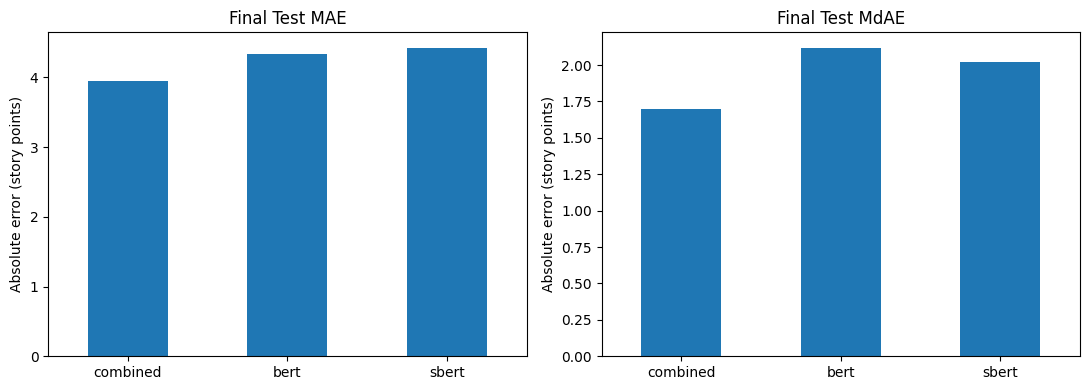

,representation,mae_mean,mae_std,mdae_mean,mdae_std,folds
0,bert,4.554500,0.280940,2.026632,0.082531,5
1,combined,4.523875,0.299933,2.096137,0.108962,5
2,sbert,4.588423,0.376282,2.024224,0.215449,5


,representation,mae,mdae,selected_epochs,input_dimensions
2,combined,3.941601,1.698759,3,1152
0,bert,4.340028,2.119053,3,768
1,sbert,4.423814,2.021961,1,384


Lowest final-test MAE: combined
Lowest final-test MdAE: combined
All outputs saved to: /content/drive/MyDrive/TAWOS_NLP/results


In [8]:
fold_frame = pd.DataFrame(fold_results)
validation_summary = (
    fold_frame.groupby("representation")
    .agg(
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        mdae_mean=("mdae", "mean"),
        mdae_std=("mdae", "std"),
        folds=("fold", "count"),
    )
    .reset_index()
)
final_frame = pd.DataFrame(
    [{"representation": name, **values} for name, values in final_results.items()]
).sort_values("mae")

fold_frame.to_csv(RESULTS_DIR / f"{SELECTED_PROJECT}_fold_metrics.csv", index=False)
validation_summary.to_csv(
    RESULTS_DIR / f"{SELECTED_PROJECT}_validation_summary.csv", index=False
)
final_frame.to_csv(RESULTS_DIR / f"{SELECTED_PROJECT}_final_test_metrics.csv", index=False)
prediction_table.to_csv(RESULTS_DIR / f"{SELECTED_PROJECT}_test_predictions.csv", index=False)

best_mae = min(final_results, key=lambda name: final_results[name]["mae"])
best_mdae = min(final_results, key=lambda name: final_results[name]["mdae"])
reproducibility = {
    "problem_statement": 10,
    "project_key": SELECTED_PROJECT,
    "seed": SEED,
    "device": str(DEVICE),
    "bert_model": BERT_MODEL,
    "sbert_model": SBERT_MODEL,
    "max_length": MAX_LENGTH,
    "test_fraction": TEST_FRACTION,
    "folds": N_FOLDS,
    "training": {
        "batch_size": TRAIN_BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "loss": "SmoothL1Loss",
    },
    "validation_summary": validation_summary.to_dict(orient="records"),
    "final_test": final_results,
    "lowest_mae": best_mae,
    "lowest_mdae": best_mdae,
    "package_versions": {
        "python": sys.version,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "torch": torch.__version__,
    },
}
(RESULTS_DIR / f"{SELECTED_PROJECT}_experiment_summary.json").write_text(
    json.dumps(reproducibility, indent=2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
final_frame.plot.bar(x="representation", y="mae", ax=axes[0], legend=False, title="Final Test MAE")
final_frame.plot.bar(x="representation", y="mdae", ax=axes[1], legend=False, title="Final Test MdAE")
for axis in axes:
    axis.set_xlabel("")
    axis.set_ylabel("Absolute error (story points)")
    axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"{SELECTED_PROJECT}_final_metrics.png", dpi=180)
plt.show()

display(validation_summary)
display(final_frame)
print("Lowest final-test MAE:", best_mae)
print("Lowest final-test MdAE:", best_mdae)
print("All outputs saved to:", RESULTS_DIR)



## Interpretation checklist for the report

- Report five validation folds separately from final held-out test results.
- Compare BERT-only, SBERT-only, and combined models using the same partitions.
- State whether fusion actually improved MAE and/or MdAE; do not assume it did.
- Discuss temporal drift, project-specific vocabulary, story-point imbalance,
  truncated input text, frozen encoders, and the single-project limitation.
- Include the selected project, date ranges, issue counts, random seed, model
  versions, fusion method, hyperparameters, and the GitHub link on page one.

